In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

In [3]:
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target


y_named = y.map({0: "Malignant", 1: "Benign"})

print("Dataset shape:", X.shape)
print(X.head())


Dataset shape: (569, 30)
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst 

In [4]:
print("\nMissing values:", X.isnull().sum().sum())
print("\nClass counts:")
print(y_named.value_counts())

# Shows that features have very different ranges (so scaling is needed)
print("\nMin and max of 3 features:")
print(X[["mean area", "mean radius", "mean smoothness"]].describe().loc[["min", "max"]])



Missing values: 0

Class counts:
target
Benign       357
Malignant    212
Name: count, dtype: int64

Min and max of 3 features:
     mean area  mean radius  mean smoothness
min      143.5        6.981          0.05263
max     2501.0       28.110          0.16340


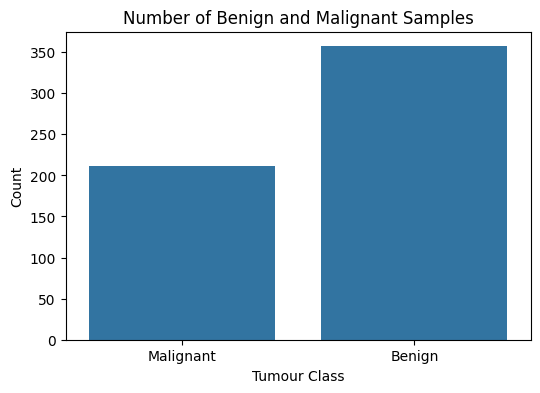

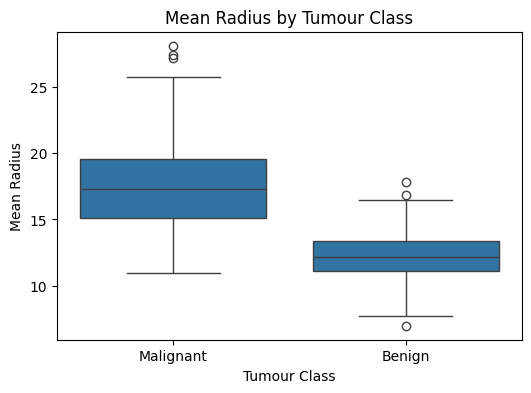

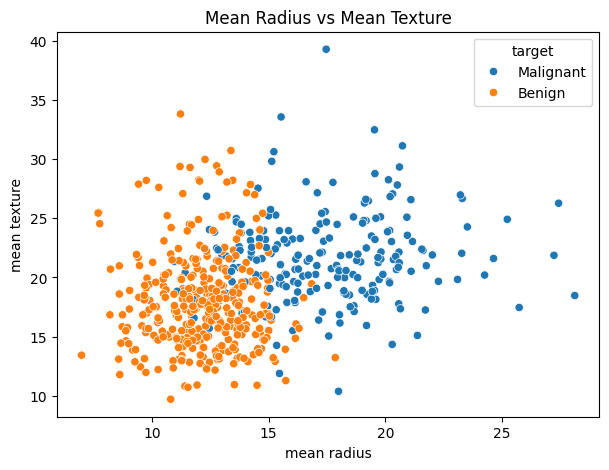

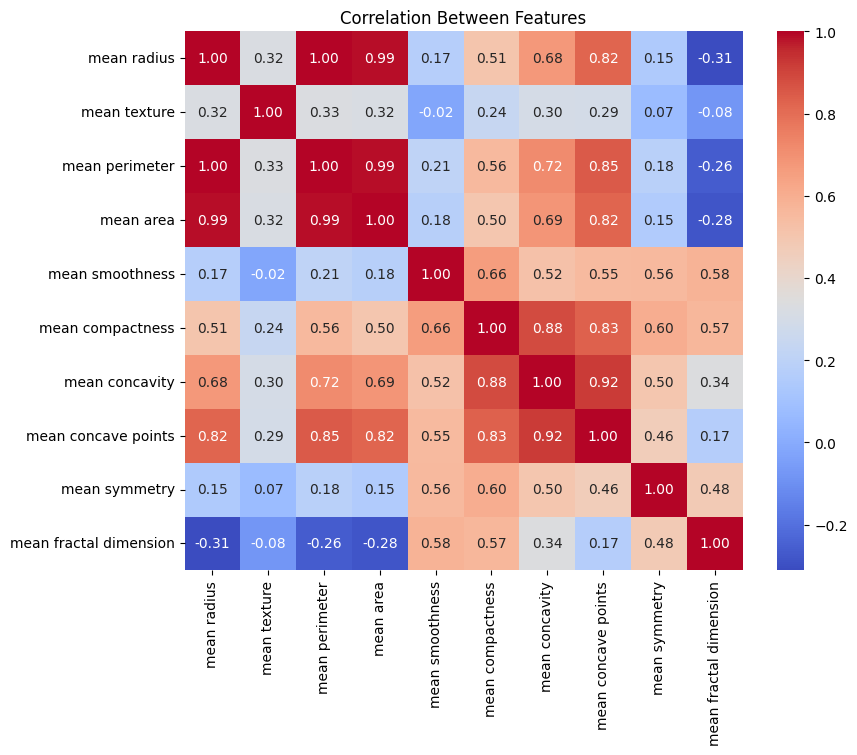

In [5]:
plt.figure(figsize=(6, 4))
sns.countplot(x=y_named)
plt.title("Number of Benign and Malignant Samples")
plt.xlabel("Tumour Class")
plt.ylabel("Count")
plt.show()

# 3.2 Do the classes differ in mean radius?
plt.figure(figsize=(6, 4))
sns.boxplot(x=y_named, y=X["mean radius"])
plt.title("Mean Radius by Tumour Class")
plt.xlabel("Tumour Class")
plt.ylabel("Mean Radius")
plt.show()

# 3.3 Scatter plot of two features
plt.figure(figsize=(7, 5))
sns.scatterplot(data=X, x="mean radius", y="mean texture", hue=y_named)
plt.title("Mean Radius vs Mean Texture")
plt.show()

# 3.4 Correlation heatmap (first 10 'mean' features)
plt.figure(figsize=(9, 7))
sns.heatmap(X.iloc[:, :10].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Between Features")
plt.show()

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("\nTraining samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

# 4.2 Scale the features (mean = 0, standard deviation = 1)
# fit_transform on training data: learns the mean/std and applies scaling
# transform on test data: uses the SAME mean/std (no peeking at test data)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)



Training samples: 455
Testing samples : 114


In [7]:
model = SVC(kernel="linear")
model.fit(X_train_scaled, y_train)
print("\nModel training completed.")


Model training completed.



Accuracy : 0.9737
Precision: 0.9859
Recall   : 0.9722
F1-score : 0.979

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.98      0.96        42
      benign       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



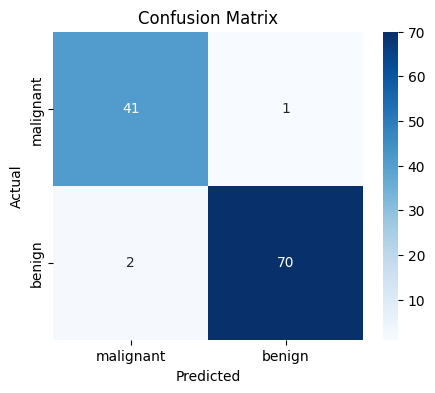

In [8]:
y_pred = model.predict(X_test_scaled)

print("\nAccuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1-score :", round(f1_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=data.target_names))

# Confusion matrix as a heatmap
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=data.target_names, yticklabels=data.target_names)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [ ]:
#Non-Linear SVM

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [10]:
X, y = make_circles(n_samples=400, noise=0.1, factor=0.4, random_state=42)

print("Dataset shape:", X.shape)
print("Class counts:", np.bincount(y))

Dataset shape: (400, 2)
Class counts: [200 200]


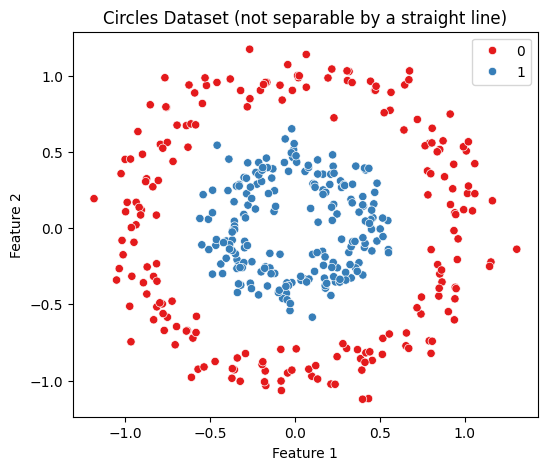

In [11]:
plt.figure(figsize=(6, 5))
sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=y, palette="Set1")
plt.title("Circles Dataset (not separable by a straight line)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [ ]:
#Non -Linear

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)
sns.set_theme(style="whitegrid", font_scale=1.1)
COLORS = {"Outer circle": "#1f77b4", "Inner circle": "#ff7f0e"}


In [14]:
X_array, y = make_circles(n_samples=600, noise=0.1, factor=0.4, random_state=42)

X = pd.DataFrame(X_array, columns=["Feature 1", "Feature 2"])
y = pd.Series(y, name="Class")
y_named = y.map({0: "Outer circle", 1: "Inner circle"})   # readable labels for plots

print("Dataset shape:", X.shape)
print("Number of features:", X.shape[1])
print("\nFirst 5 rows:")
print(X.head())


Dataset shape: (600, 2)
Number of features: 2

First 5 rows:
   Feature 1  Feature 2
0  -0.580232   0.792751
1  -0.313055   0.247863
2   0.153312  -0.306001
3   0.046745   0.975753
4  -0.792095  -0.722212


In [15]:
print("\n--- DATA QUALITY CHECKS ---")
print("Missing values  :", X.isnull().sum().sum())
print("Duplicate rows  :", X.duplicated().sum())

print("\nClass distribution:")
print(y_named.value_counts())

print("\nSummary statistics:")
print(X.describe().round(2))




--- DATA QUALITY CHECKS ---
Missing values  : 0
Duplicate rows  : 0

Class distribution:
Class
Outer circle    300
Inner circle    300
Name: count, dtype: int64

Summary statistics:
       Feature 1  Feature 2
count     600.00     600.00
mean        0.00       0.01
std         0.55       0.54
min        -1.17      -1.16
25%        -0.38      -0.34
50%        -0.00       0.02
75%         0.37       0.38
max         1.12       1.24


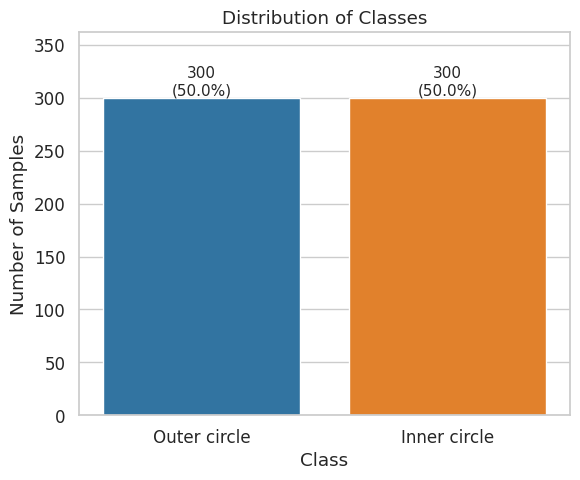

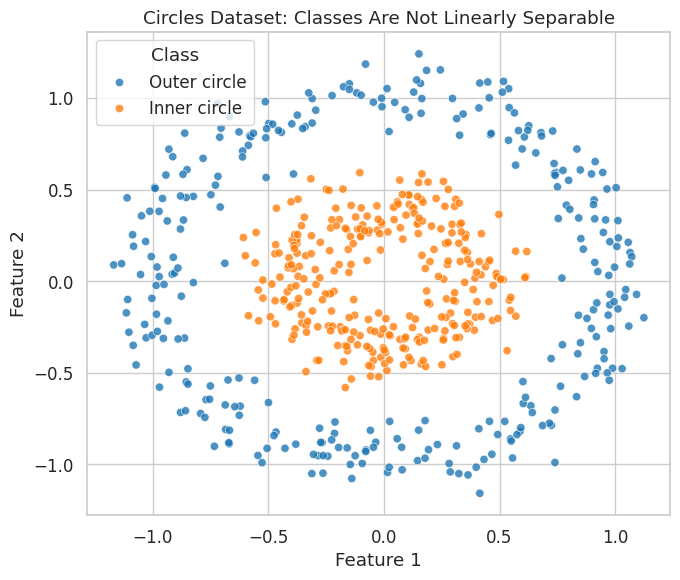

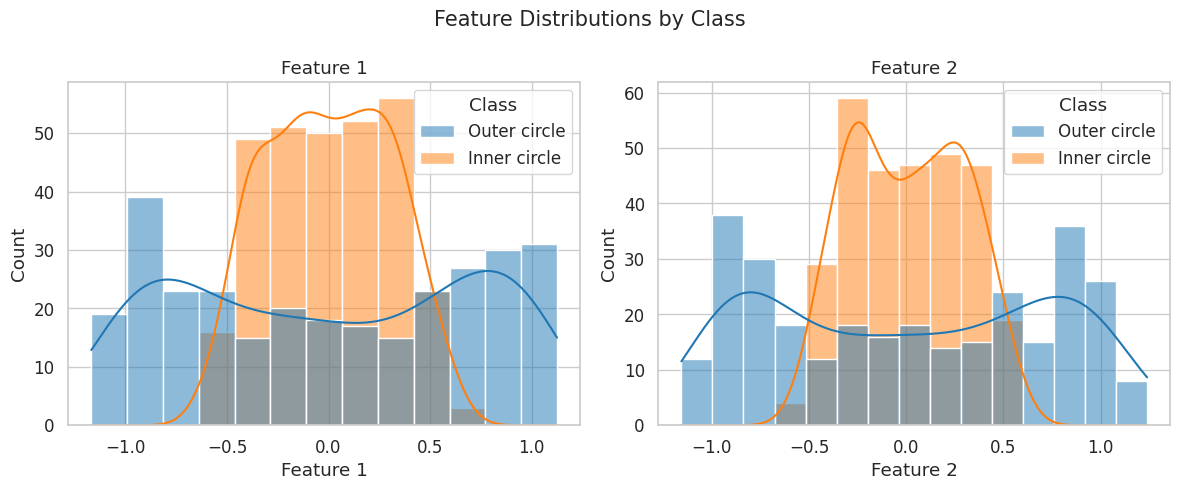

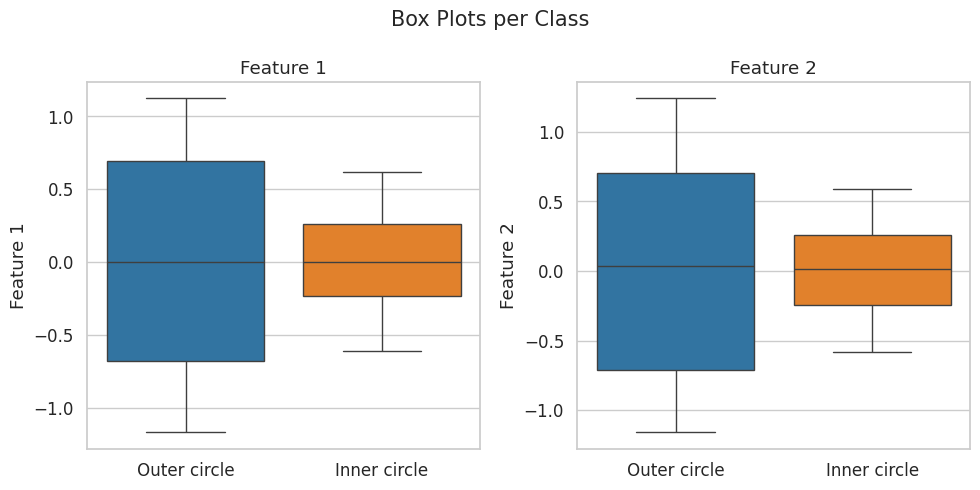

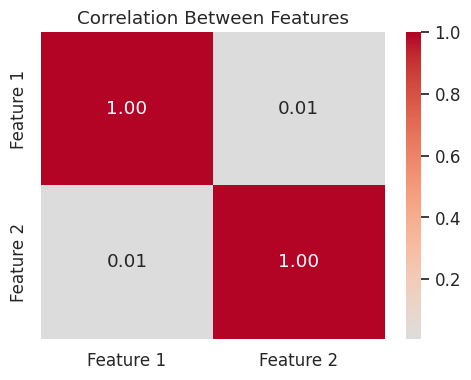

In [16]:
# 3.1 Class distribution with percentages
plt.figure(figsize=(6, 5))
ax = sns.countplot(x=y_named, hue=y_named, palette=COLORS,
                   order=["Outer circle", "Inner circle"], legend=False)
total = len(y_named)
for bar in ax.patches:
    h = bar.get_height()
    ax.annotate(f"{int(h)}\n({h / total * 100:.1f}%)",
                (bar.get_x() + bar.get_width() / 2, h),
                ha="center", va="bottom", fontsize=11)
ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
plt.title("Distribution of Classes")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

# 3.2 Scatter plot - this shows WHY a straight line cannot separate the classes
plt.figure(figsize=(7, 6))
sns.scatterplot(data=X, x="Feature 1", y="Feature 2",
                hue=y_named, palette=COLORS, alpha=0.8, edgecolor="white")
plt.title("Circles Dataset: Classes Are Not Linearly Separable")
plt.legend(title="Class")
plt.tight_layout()
plt.show()

# 3.3 Feature distributions by class
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, feature in zip(axes, X.columns):
    sns.histplot(data=X.assign(Class=y_named), x=feature, hue="Class",
                 palette=COLORS, kde=True, alpha=0.5, ax=ax)
    ax.set_title(feature)
plt.suptitle("Feature Distributions by Class", fontsize=15)
plt.tight_layout()
plt.show()

# 3.4 Box plots (spread and outliers per class)
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, feature in zip(axes, X.columns):
    sns.boxplot(x=y_named, y=X[feature], hue=y_named, palette=COLORS,
                order=["Outer circle", "Inner circle"], legend=False, ax=ax)
    ax.set_title(feature)
    ax.set_xlabel("")
plt.suptitle("Box Plots per Class", fontsize=15)
plt.tight_layout()
plt.show()

# 3.5 Correlation heatmap
plt.figure(figsize=(5, 4))
sns.heatmap(X.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Between Features")
plt.tight_layout()
plt.show()


Training samples: 480
Testing samples : 120
Train class ratio: 0.5
Test  class ratio: 0.5


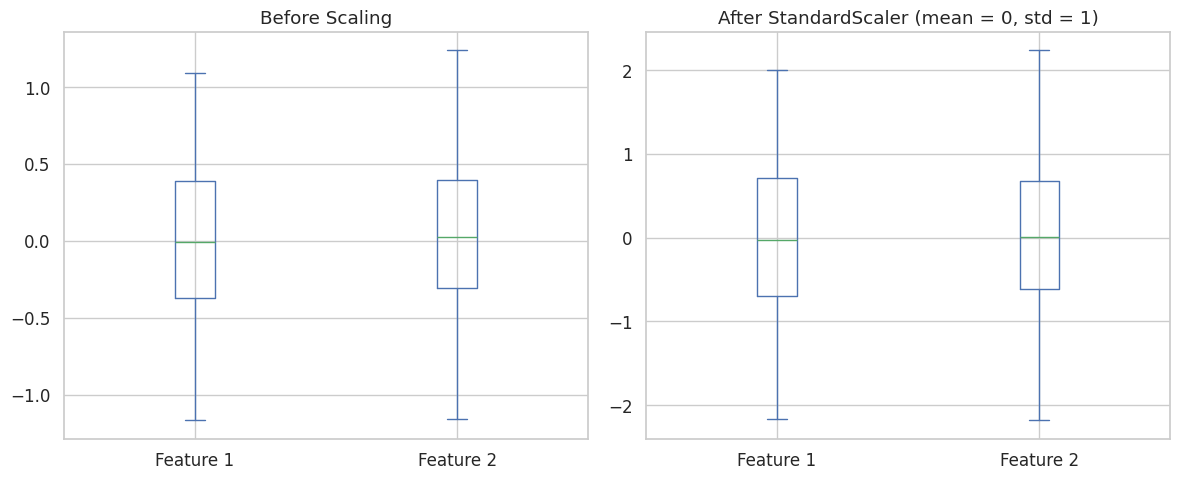

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("\nTraining samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])
print("Train class ratio:", round(y_train.mean(), 3))
print("Test  class ratio:", round(y_test.mean(), 3))

# 4.2 Show the effect of scaling (before vs after)
# The scaler is fitted ONLY on training data to avoid data leakage.
scaler_demo = StandardScaler().fit(X_train)
X_train_scaled = pd.DataFrame(scaler_demo.transform(X_train), columns=X.columns)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
X_train.plot(kind="box", ax=axes[0])
axes[0].set_title("Before Scaling")
X_train_scaled.plot(kind="box", ax=axes[1])
axes[1].set_title("After StandardScaler (mean = 0, std = 1)")
plt.tight_layout()
plt.show()

# 4.3 Pipelines = imputer -> scaler -> model
# RBF-SVM is distance based, so scaling is very important.
linear_svm = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", SVC(kernel="linear", class_weight="balanced"))
])

rbf_svm = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", SVC(kernel="rbf", C=1, gamma="scale", class_weight="balanced"))
])


In [18]:
linear_svm.fit(X_train, y_train)
rbf_svm.fit(X_train, y_train)
print("\nModel training completed.")


Model training completed.



RBF (NON-LINEAR) SVM EVALUATION
-------------------------------
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-score : 1.0
ROC-AUC  : 1.0

Classification Report:
              precision    recall  f1-score   support

Outer circle       1.00      1.00      1.00        60
Inner circle       1.00      1.00      1.00        60

    accuracy                           1.00       120
   macro avg       1.00      1.00      1.00       120
weighted avg       1.00      1.00      1.00       120

Linear SVM accuracy: 0.5667
RBF SVM accuracy   : 1.0000


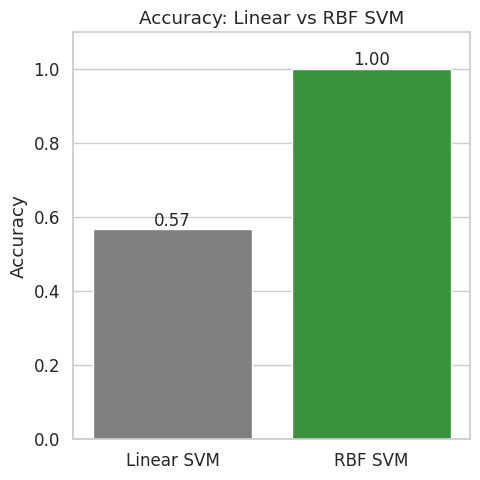

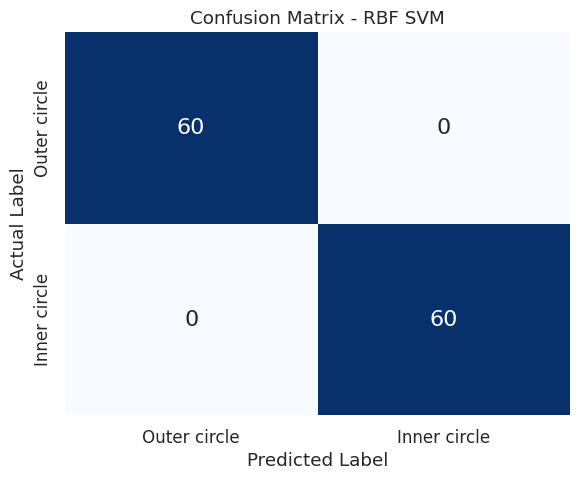

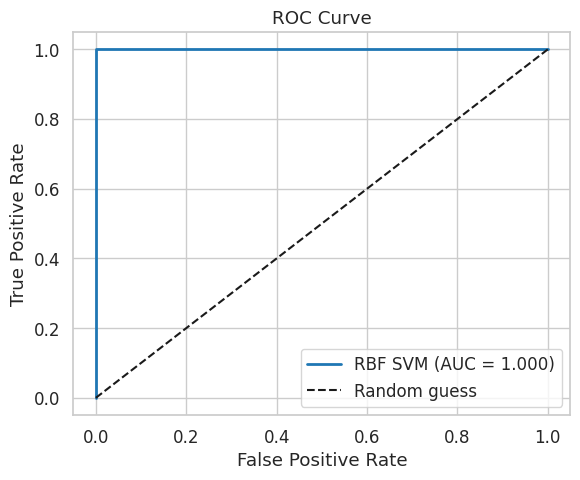

In [19]:
y_pred = rbf_svm.predict(X_test)
y_scores = rbf_svm.decision_function(X_test)   # distance from the boundary

print("\nRBF (NON-LINEAR) SVM EVALUATION")
print("-------------------------------")
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1-score :", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_scores), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred,
                            target_names=["Outer circle", "Inner circle"]))

# 6.1 Linear vs RBF comparison
linear_acc = accuracy_score(y_test, linear_svm.predict(X_test))
rbf_acc = accuracy_score(y_test, y_pred)
print(f"Linear SVM accuracy: {linear_acc:.4f}")
print(f"RBF SVM accuracy   : {rbf_acc:.4f}")

plt.figure(figsize=(5, 5))
ax = sns.barplot(x=["Linear SVM", "RBF SVM"], y=[linear_acc, rbf_acc],
                 hue=["Linear SVM", "RBF SVM"],
                 palette=["#7f7f7f", "#2ca02c"], legend=False)
for bar in ax.patches:
    ax.annotate(f"{bar.get_height():.2f}",
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom", fontsize=12)
plt.ylim(0, 1.1)
plt.title("Accuracy: Linear vs RBF SVM")
plt.ylabel("Accuracy")
plt.tight_layout()
plt.show()

# 6.2 Confusion matrix heatmap
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Outer circle", "Inner circle"],
            yticklabels=["Outer circle", "Inner circle"],
            annot_kws={"size": 16})
plt.title("Confusion Matrix - RBF SVM")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

# 6.3 ROC curve
fpr, tpr, _ = roc_curve(y_test, y_scores)
auc = roc_auc_score(y_test, y_scores)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color="#1f77b4", lw=2, label=f"RBF SVM (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

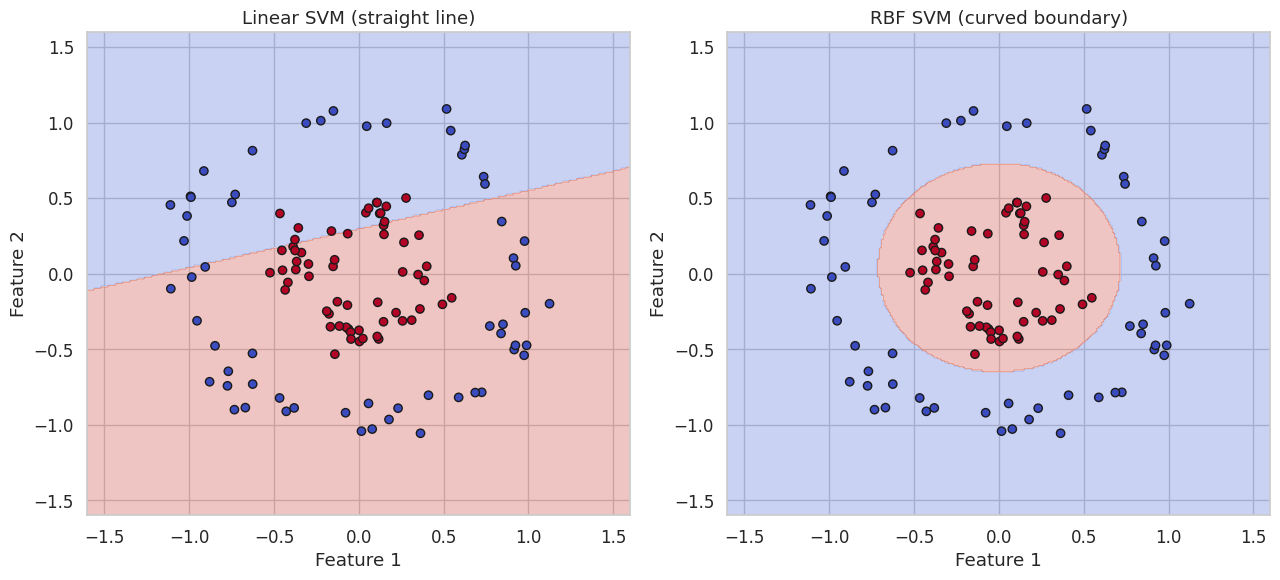

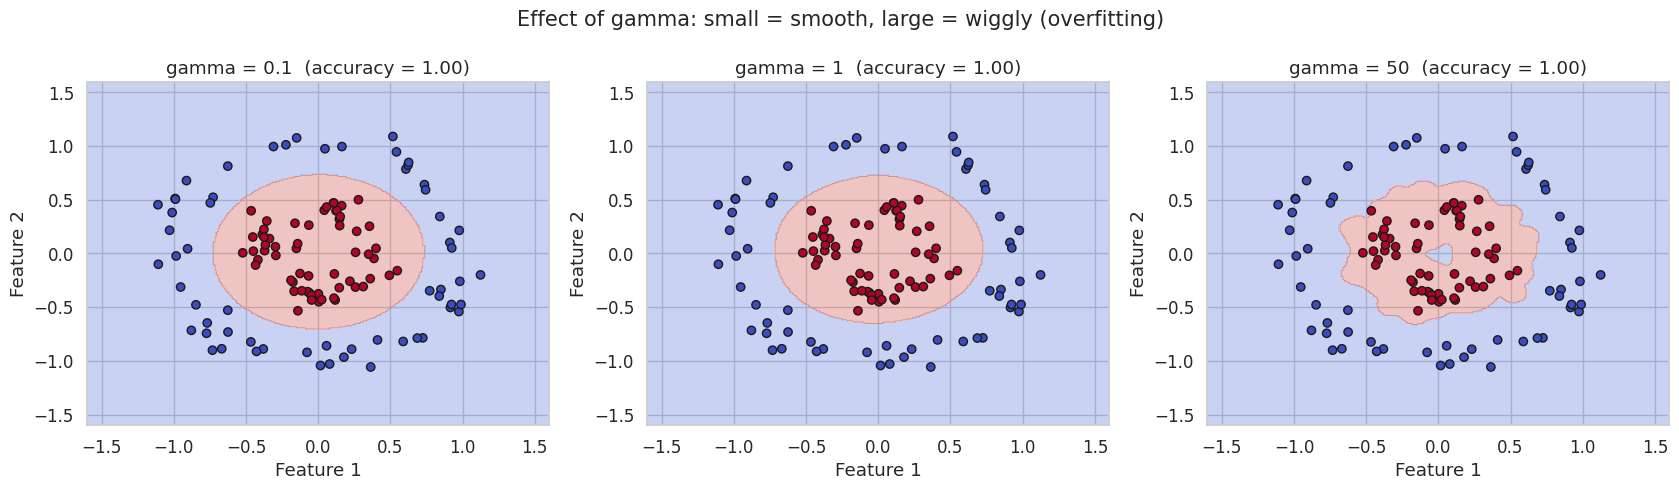

In [21]:
def plot_boundary(model, title, ax):

    xx, yy = np.meshgrid(np.linspace(-1.6, 1.6, 300),
                         np.linspace(-1.6, 1.6, 300))
    grid = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=X.columns)


    Z = model.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")


    ax.scatter(X_test["Feature 1"], X_test["Feature 2"],
               c=y_test, cmap="coolwarm", edgecolor="k")
    ax.set_title(title)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")



fig, axes = plt.subplots(1, 2, figsize=(13, 6))
plot_boundary(linear_svm, "Linear SVM (straight line)", axes[0])
plot_boundary(rbf_svm, "RBF SVM (curved boundary)", axes[1])
plt.tight_layout()
plt.show()


fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, g in zip(axes, [0.1, 1, 50]):
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", C=1, gamma=g))
    ])
    model.fit(X_train, y_train)
    acc = accuracy_score(y_test, model.predict(X_test))
    plot_boundary(model, f"gamma = {g}  (accuracy = {acc:.2f})", ax)
plt.suptitle("Effect of gamma: small = smooth, large = wiggly (overfitting)",
             fontsize=15)
plt.tight_layout()
plt.show()
